# Training infrastructure and TF-IDF baseline, Phase 1

I build the machinery the training runs on: I define the config format, I
define the run record format, I build the evaluation harness, and I run the
TF-IDF baseline that every neural model must beat.

Contents:
1. Define the config format
2. Define the run record format
3. Build the evaluation harness
4. Run the TF-IDF baseline
5. What the baseline means

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

DATA = Path.home() / "workspace/ai-customer-support/svr-data"
TABLES = DATA / "final"
FIGURES = Path.home() / "workspace/ai-customer-support/phase-1-examples/figures"

FIELDS = ["complaint_category", "complaint_urgency", "customer_state", "churn_risk"]

## 1. Define the config format

I define one config format for every experiment. It holds the model, the
hyperparameters, the seed, the dataset version, and the split. Every
experiment uses this same format, so nothing is left implicit.

In [2]:
config = {
    "model": "EgyBERT",
    "learning_rate": 2e-5,
    "batch_size": 16,
    "epochs": 3,
    "seed": 42,
    "dataset_version": "v2",
    "split": "train",
}
print(config)

{'model': 'EgyBERT', 'learning_rate': 2e-05, 'batch_size': 16, 'epochs': 3, 'seed': 42, 'dataset_version': 'v2', 'split': 'train'}


## 2. Define the run record format

I define one run record format for every experiment. It holds the run ID, the
hypothesis, the single factor that changed, the conditions held constant, the
measures, and the artifacts. One variable changes per experiment, and the
record says which one.

In [3]:
run_record = {
    "run_id": "001",
    "hypothesis": "EgyBERT beats MARBERTv2 on complaint_category",
    "changed_factor": "model",
    "held_constant": "lr 2e-5, batch 16, epochs 3",
    "measures": {},
    "artifacts": ["checkpoint.pt", "predictions.csv"],
}
print(run_record)

{'run_id': '001', 'hypothesis': 'EgyBERT beats MARBERTv2 on complaint_category', 'changed_factor': 'model', 'held_constant': 'lr 2e-5, batch 16, epochs 3', 'measures': {}, 'artifacts': ['checkpoint.pt', 'predictions.csv']}


## 3. Build the evaluation harness

I build the harness before any real model exists, so I demonstrate it on
small synthetic arrays. It takes the true labels and the predicted labels and
it returns the macro-F1, the accuracy, and the confusion matrix, in one fixed
format.

In [4]:
def evaluate(y_true, y_pred):
    # Return macro-F1, accuracy, and the confusion matrix for one field.
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
    }

# Mock predictions, so the harness works before any real model exists.
y_true_mock = ["a", "b", "a", "b", "c", "a"]
y_pred_mock = ["a", "b", "b", "b", "c", "a"]
result = evaluate(y_true_mock, y_pred_mock)
print("macro-F1:", round(result["macro_f1"], 4))
print("accuracy:", round(result["accuracy"], 4))
print("confusion matrix:")
print(result["confusion_matrix"])

macro-F1: 0.8667
accuracy: 0.8333
confusion matrix:
[[2 1 0]
 [0 2 0]
 [0 0 1]]


## 4. Run the TF-IDF baseline

I run the baseline the neural models must beat: TF-IDF features plus logistic
regression, one model per field, trained on the 4,031 train rows and evaluated
on the 1,136 validation rows. I use class_weight balanced because the classes
are imbalanced, and I keep it fast with max_features 5000 and ngram_range 1-2.

In [5]:
train = pd.read_csv(TABLES / "clean_training_train.csv", usecols=["text_norm"] + FIELDS)
val = pd.read_csv(TABLES / "clean_training_val.csv", usecols=["text_norm"] + FIELDS)
print(f"train rows: {len(train)}, val rows: {len(val)}")

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train = vectorizer.fit_transform(train["text_norm"].fillna(""))
X_val = vectorizer.transform(val["text_norm"].fillna(""))

baseline = {}
for field in FIELDS:
    clf = LogisticRegression(class_weight="balanced", max_iter=1000)
    clf.fit(X_train, train[field])
    pred = clf.predict(X_val)
    res = evaluate(val[field], pred)
    baseline[field] = res["macro_f1"]
    print(f"{field}: macro-F1 {res['macro_f1']:.4f}, accuracy {res['accuracy']:.4f}")

print(baseline)

train rows: 4031, val rows: 1136


complaint_category: macro-F1 0.7261, accuracy 0.7456


complaint_urgency: macro-F1 0.6789, accuracy 0.7403


customer_state: macro-F1 0.5561, accuracy 0.6945
churn_risk: macro-F1 0.8840, accuracy 0.9974
{'complaint_category': 0.7260975461486067, 'complaint_urgency': 0.6789372290760127, 'customer_state': 0.5561483154427082, 'churn_risk': 0.8839513739912146}


## 5. What the baseline means

I plot the four validation macro-F1 numbers, then I read them. The baseline is
the reference every neural model must beat: a neural model proves it adds
value only when it beats these numbers on the same validation split, with the
same seeds and the same config format. A field with a low baseline macro-F1 is
the hard one, and the churn field is the one to watch because only a few
validation rows are at risk.

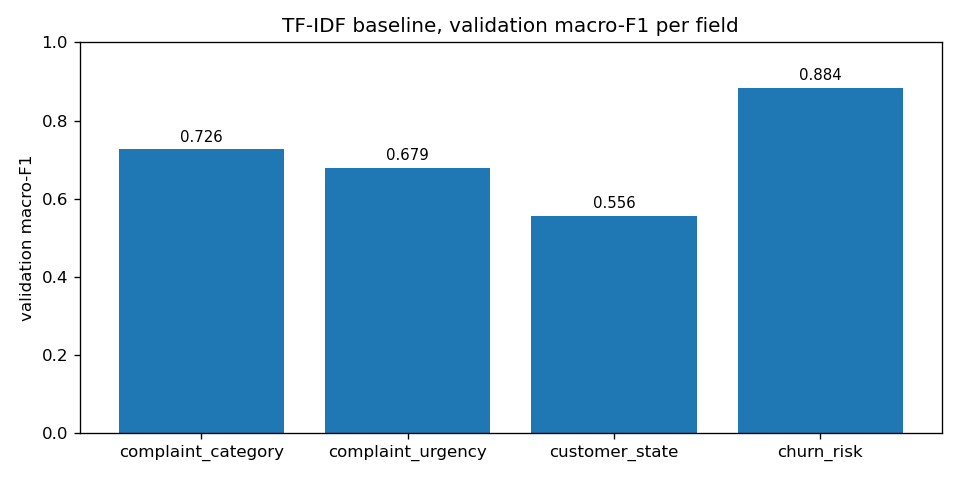

In [6]:
import matplotlib
matplotlib.use("Agg")
from matplotlib.figure import Figure

from IPython.display import Image

fig = Figure(figsize=(8, 4))
ax = fig.add_subplot(111)
fields = list(baseline.keys())
scores = [baseline[f] for f in fields]
ax.bar(fields, scores)
ax.set_ylabel("validation macro-F1")
ax.set_title("TF-IDF baseline, validation macro-F1 per field")
ax.set_ylim(0, 1)
for i, s in enumerate(scores):
    ax.text(i, s + 0.02, f"{s:.3f}", ha="center", fontsize=9)
fig.tight_layout()
FIGURES.mkdir(exist_ok=True)
out = FIGURES / "baseline_macro_f1.png"
fig.savefig(out, dpi=120)
Image(str(out))

In [7]:
best = max(baseline, key=baseline.get)
worst = min(baseline, key=baseline.get)
mean_f1 = sum(baseline.values()) / len(baseline)
print(f"Strongest field: {best} at {baseline[best]:.4f}")
print(f"Weakest field: {worst} at {baseline[worst]:.4f}")
print(f"Mean macro-F1 across fields: {mean_f1:.4f}")
print("These four numbers are the bar. EgyBERT and MARBERTv2 must beat them.")

Strongest field: churn_risk at 0.8840
Weakest field: customer_state at 0.5561
Mean macro-F1 across fields: 0.7113
These four numbers are the bar. EgyBERT and MARBERTv2 must beat them.
